Does a smaller time step improve your simulation?
weekly challenge #1

Import libraries

In [219]:
import numpy as np
import matplotlib.pyplot as plt

Set constants:

In [220]:
r = 10_000 #ohm
c = 100*(10**-6) #F
v0 = 5 #Volt
tau = r*c
t = 0
tfinal=5*tau

Function according to forward Euler:
V[n+1] = V[n] + dt x (dV/dt evaluated at V[n])

In [221]:
def volt_vs_time (dt, r=r, c=c, v0=v0, t=t, tfinal=tfinal):
    times = []
    voltages = []
    v = v0
    times.append(t)
    voltages.append(v)
    while t <= tfinal:
        dv = -v/(r*c)
        v = v + dt * dv
        times.append(t)
        voltages.append(v)
        t += dt
    return voltages, times



Run function for the three times

In [222]:
v0p2, t0p2 = volt_vs_time(0.2)
v0p1, t0p1 = volt_vs_time(0.1)
v0p05, t0p05 = volt_vs_time(0.05)

find exact solution

In [223]:
v_exact = [v0]
t_exact = [t]
dt = 0.05
while t<=tfinal:
    v = v0 * np.exp(-t/tau)
    v_exact.append(v)
    t_exact.append(t)
    t+=dt


Calculate Error

In [224]:
def get_max_error(v_dt, t_dt):
    errors = np.array([])
    for v,t in zip(v_dt, t_dt):
        e = np.abs(v - (v0 * np.exp(-t/tau)))
        errors = np.append(errors, e)
    return np.max(errors)


In [ ]:
error_0p2 = get_max_error(v0p2, t0p2)
error_0p1 = get_max_error(v0p1, t0p1)
error_0p05 = get_max_error(v0p05, t0p05)
errors = [error_0p05,error_0p1,error_0p2]
dts = [0.05,0.1,0.2]

In [226]:
print(dts)

[0.05, 0.1, 0.2]


Plotting Function:

C:\Users\laine\AppData\Local\Temp\ipykernel_95136\3729347550.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


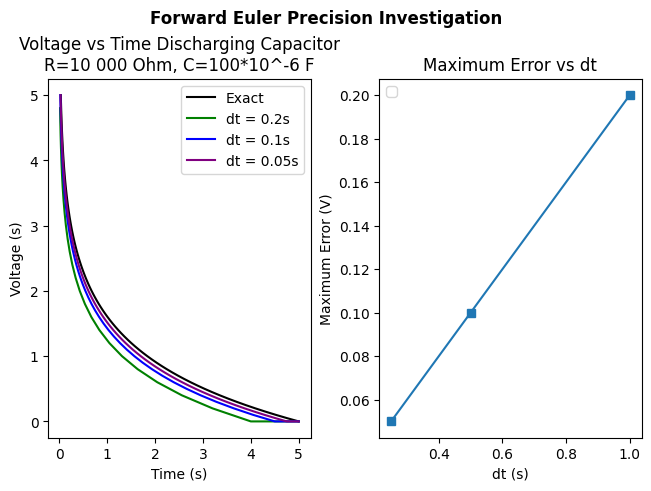

In [227]:
fig, axs = plt.subplots(1,2, constrained_layout=True)
fig.suptitle("Forward Euler Precision Investigation", weight="bold")
axs[0].plot(v_exact, t_exact, label = "Exact", color = 'black')
axs[0].plot(v0p2, t0p2, label = "dt = 0.2s", color = 'green')
axs[0].plot(v0p1, t0p1, label = "dt = 0.1s", color = 'blue')
axs[0].plot(v0p05, t0p05, label = "dt = 0.05s", color = 'purple')
axs[0].set(xlabel = 'Time (s)' , ylabel='Voltage (s)', title="Voltage vs Time Discharging Capacitor\nR=10 000 Ohm, C=100*10^-6 F")

axs[1].plot(errors, dts, marker="s")
axs[1].set(title="Maximum Error vs dt", xlabel = "dt (s)", ylabel = "Maximum Error (V)")
for ax in axs.flat:
    ax.legend()